In [85]:
import os 

os.listdir()

['bin',
 'boot',
 'dev',
 'etc',
 'home',
 'lib',
 'lib32',
 'lib64',
 'libx32',
 'media',
 'mnt',
 'opt',
 'proc',
 'root',
 'run',
 'sbin',
 'srv',
 'sys',
 'tmp',
 'usr',
 'var',
 '.launch',
 'workspace',
 '.first_boot_complete',
 'venv',
 'chest_xray_fine_tuning.keras',
 '.ipynb_checkpoints',
 '.dockerenv',
 'NGC-DL-CONTAINER-LICENSE',
 'cuda-keyring_1.1-1_all.deb']

## EDA

In [86]:
#Charger le dataset de radiographies thoraciques fourni pour le projet.
%pip install kagglehub
import kagglehub

path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)


Note: you may need to restart the kernel to use updated packages.
Path to dataset files: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


In [87]:
# Explorer la structure des dossiers et identifier les classes présentes.
from pathlib import Path

data_dir = Path(path) / "chest_xray"

train_dir = data_dir / "train"
test_dir = data_dir / "test"
val_dir = data_dir / "val"

print("Train :", train_dir)
print("Test :", test_dir)
print("Validation :", val_dir)

Train : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/train
Test : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/test
Validation : /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/val


In [88]:
# Vérifier le nombre d'images disponibles dans chaque classe.
# Vérifier la répartition des images entre les classes NORMAL et PNEUMONIA.
for nom, dossier in [
    ("Train", train_dir),
    ("Validation", val_dir),
    ("Test", test_dir)
]:
    print(f"\n{nom} :")

    for classe in ["NORMAL", "PNEUMONIA"]:
        classe_dir = dossier / classe

        images = [
            f for f in classe_dir.iterdir()
            if f.is_file()
        ]

        print(f"{classe} : {len(images)} images")



Train :
NORMAL : 1341 images
PNEUMONIA : 3875 images

Validation :
NORMAL : 8 images
PNEUMONIA : 8 images

Test :
NORMAL : 234 images
PNEUMONIA : 390 images


In [89]:
# Identifier les éventuels problèmes liés aux images et gérer les erreurs de chargement.
%pip install plt
from PIL import Image

for nom, dossier in [
    ("Train", train_dir),
    ("Test", test_dir),
    ("Validation", val_dir)
]:
    erreurs = []

    for classe in dossier.iterdir():
        if classe.is_dir():
            for images in classe.iterdir():
                try:
                    with Image.open(images) as img:
                        img.verify()
                except Exception:
                    erreurs.append(images)

    print(f"{nom} : {len(erreurs)} images problématiques")

Note: you may need to restart the kernel to use updated packages.
Train : 0 images problématiques
Test : 0 images problématiques
Validation : 0 images problématiques


In [90]:
for nom, dossier in [
    ("Train", train_dir),
    ("Test", test_dir),
    ("Validation", val_dir)
]:
    for fichier in dossier.iterdir():
        if fichier.is_dir():
            for image in list(fichier.iterdir())[:1]:
                with Image.open(image) as img:
                    print(
                        f"Ensemble : {nom} | "
                        f"Classe : {fichier.name} | "
                        f"Image : {image.name} | "
                        f"Taille : {img.size} | "
                        f"Mode : {img.mode} | "
                        f"Format : {img.format}"
                    )

Ensemble : Train | Classe : NORMAL | Image : IM-0115-0001.jpeg | Taille : (2090, 1858) | Mode : L | Format : JPEG
Ensemble : Train | Classe : PNEUMONIA | Image : person1000_bacteria_2931.jpeg | Taille : (1152, 760) | Mode : L | Format : JPEG
Ensemble : Test | Classe : NORMAL | Image : IM-0001-0001.jpeg | Taille : (1857, 1317) | Mode : L | Format : JPEG
Ensemble : Test | Classe : PNEUMONIA | Image : person100_bacteria_475.jpeg | Taille : (1106, 762) | Mode : L | Format : JPEG
Ensemble : Validation | Classe : NORMAL | Image : NORMAL2-IM-1427-0001.jpeg | Taille : (1776, 1416) | Mode : L | Format : JPEG
Ensemble : Validation | Classe : PNEUMONIA | Image : person1946_bacteria_4874.jpeg | Taille : (968, 592) | Mode : L | Format : JPEG


In [91]:
# Charger les images : créer une vraie validation à partir du dossier train.
# Le dossier val original du dataset contient seulement 16 images : il est trop petit.
# Redimensionner les images à une taille fixe de 180 × 180 pixels et les convertir au format RGB.

import tensorflow as tf

IMG_SIZE = (180, 180)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=False
)

# Garder le dossier test complètement séparé pour l'évaluation finale.
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    shuffle=False
)

# Précharger les lots suivants sans charger tout le dataset en mémoire.
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# print("Classes :", train_ds.class_names)


Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.


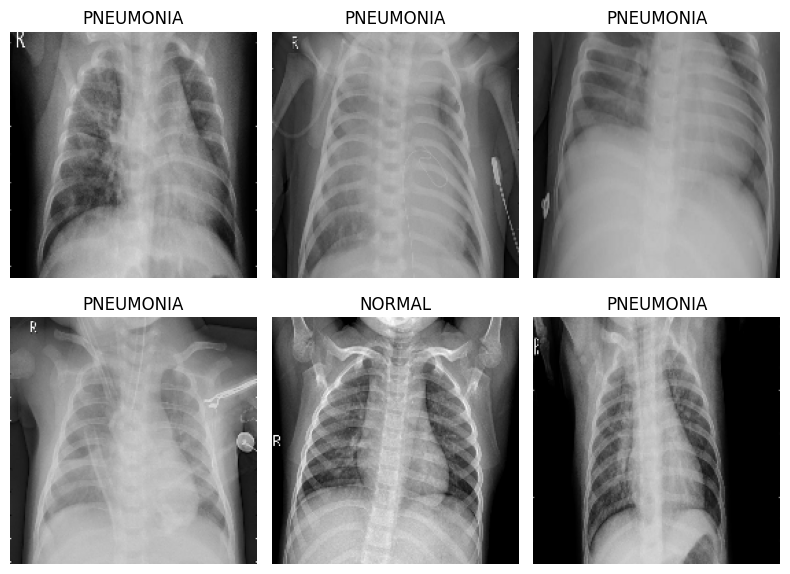

In [92]:
#Visualisation des radiographies.
import matplotlib.pyplot as plt


class_names =["NORMAL", "PNEUMONIA"]

for images, labels in train_ds.take(1):
    plt.figure(figsize=(8, 6))

    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy().squeeze())])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [93]:
import numpy as np
%pip install scikit-learn
from sklearn.utils.class_weight import compute_class_weight

y_train = np.concatenate([
    labels.numpy().ravel()
    for images, labels in train_ds
]).astype(int)

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(label): float(weight)
    for label, weight in zip(classes, weights)
}

print("Poids des classes :", class_weights)

Note: you may need to restart the kernel to use updated packages.
Poids des classes : {0: 1.9448173005219984, 1: 0.6730322580645162}


In [94]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Arrêter si la validation ne s'améliore plus et restaurer les meilleurs poids.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

# Réduire le taux d'apprentissage si val_loss stagne.
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)


## CNN 

In [135]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

model = Sequential([
    # Entrée : images 180 × 180 avec 3 canaux
    Input(shape=(180, 180, 3)),

    # Normalisation : valeurs de 0-255 vers 0-1
    Rescaling(1./255),

    # Bloc convolutionnel 1
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Bloc convolutionnel 2
    Conv2D(64, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # Bloc convolutionnel 3
    Conv2D(128, (3, 3), activation="relu"),
    MaxPooling2D((2, 2)),

    # GlobalAveragePooling2D remplace Flatten pour réduire le nombre de paramètres
    GlobalAveragePooling2D(),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

model.summary()


Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_11 (Rescaling)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 178, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 89, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 87, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 43, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 41, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_11     │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,377 (364.75 KB)

 Trainable params: 93,377 (364.75 KB)

 Non-trainable params: 0 (0.00 B)

In [136]:
from tensorflow.keras.metrics import BinaryAccuracy ,Precision,Recall,AUC
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            BinaryAccuracy(name="accuracy"),
            Precision(name="precision"),
            Recall(name="recall"),
            AUC(name="auc"),
        ]
)

In [143]:
import time


start = time.time()
history = model.fit(
    train_ds,
    epochs=15,
    class_weight=class_weights,
    validation_data=val_ds,
    callbacks=[early_stopping, reduce_lr]
)

end = time.time()
training_duration = end - start

print(f"Durée d'entraînement : {training_duration:.2f} secondes")
print(f"Durée en minutes : {training_duration / 60:.2f} minutes")


Epoch 1/15


163/163 ━━━━━━━━━━━━━━━━━━━━ 11s 41ms/step - accuracy: 0.8617 - auc: 0.9389 - loss: 0.3297 - precision: 0.9557 - recall: 0.8557 - val_accuracy: 0.8125 - val_auc: 0.8594 - val_loss: 0.4637 - val_precision: 0.7273 - val_recall: 1.0000 - learning_rate: 2.5000e-04
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.8691 - auc: 0.9430 - loss: 0.2980 - precision: 0.9646 - recall: 0.8575 - val_accuracy: 0.6250 - val_auc: 0.8594 - val_loss: 0.6594 - val_precision: 0.5714 - val_recall: 1.0000 - learning_rate: 2.5000e-04
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.8739 - auc: 0.9457 - loss: 0.2915 - precision: 0.9603 - recall: 0.8679
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
163/163 ━━━━━━━━━━━━━━━━━━━━ 7s 44ms/step - accuracy: 0.8739 - auc: 0.9457 - loss: 0.2915 - precision: 0.9604 - recall: 0.8679 - val_accuracy: 0.8125 - val_auc: 0.8594 - val_loss: 0.5407 - val_precision: 0.7273 - val_recall: 1.0000 - learning_rate: 2.500

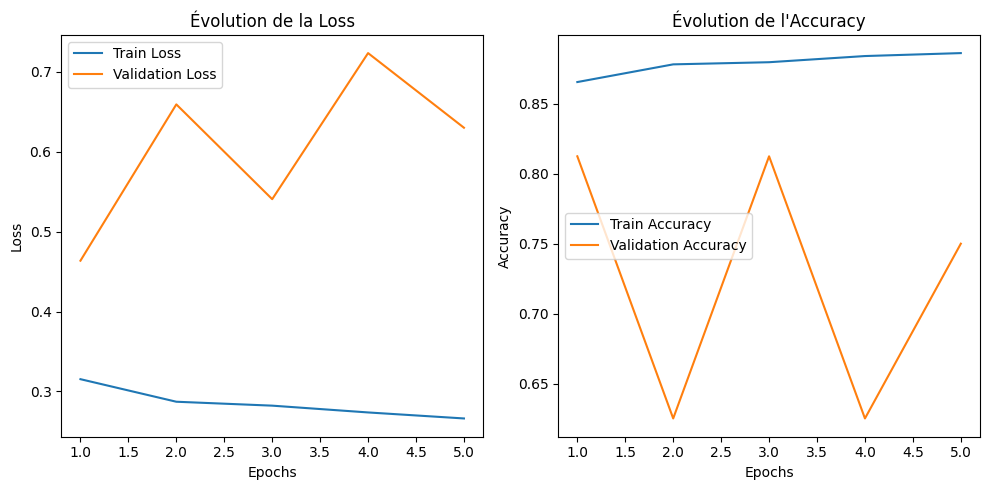

In [144]:
#visualiser les courbes d'apprentissage
train_loss =history.history["loss"]
val_loss =history.history["val_loss"]

train_accuracy =history.history["accuracy"]
val_accuracy =history.history["val_accuracy"]

epochs =range(1,len(train_loss) + 1)

plt.figure(figsize=(10,5))
plt.subplot(1, 2, 1)
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.title("Évolution de la Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracy, label="Train Accuracy")
plt.plot(epochs, val_accuracy, label="Validation Accuracy")
plt.title("Évolution de l'Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

In [145]:
results = model.evaluate(test_ds, return_dict=True)

for metric, value in results.items():
    print(f"{metric} : {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.8235 - auc: 0.5965 - loss: 0.4065 - precision: 0.4965 - recall: 0.5499    
accuracy : 0.8173
auc : 0.8932
loss : 0.4137
precision : 0.8791
recall : 0.8205


In [146]:
import numpy as np

# y_true et y_prob doivent provenir du même test_ds, dans le même ordre.
y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

y_prob = model.predict(test_ds, verbose=1).ravel()

# Seuil standard ; ne le régler qu'avec les données de validation, pas le test.
THRESHOLD = 0.5
y_pred = (y_prob >= THRESHOLD).astype(int)


20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step


In [147]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

              precision    recall  f1-score   support

      NORMAL       0.73      0.81      0.77       234
   PNEUMONIA       0.88      0.82      0.85       390

    accuracy                           0.82       624
   macro avg       0.80      0.82      0.81       624
weighted avg       0.82      0.82      0.82       624



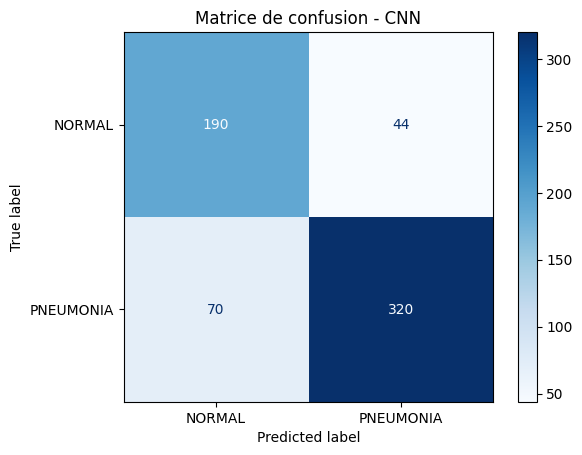

In [148]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    display_labels=["NORMAL", "PNEUMONIA"],
    cmap="Blues"
)

plt.title("Matrice de confusion - CNN")
plt.show()

In [149]:
model.save("chest_xray_cnn.keras")

In [150]:
from tensorflow import keras

model = keras.models.load_model("chest_xray_cnn.keras")

## MobilNetV2 transfer learning 


In [151]:
import tensorflow as tf
from tensorflow.keras import layers, models

IMG_SIZE = (180, 180)
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    input_shape=(180, 180, 3), 
    include_top=False,
)
base_model.trainable = False
print("mobileNetV2 chargé avec succès")


/tmp/ipykernel_874/2933677861.py:5: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


mobileNetV2 chargé avec succès


In [152]:
import tensorflow as tf
from tensorflow.keras import layers, Sequential

model_mobilenet = Sequential([
    # 1.images RGB de 180 x 180
    layers.Input(shape=(180, 180, 3)),

    # 2. Pretraitement  MobileNetV2
    layers.Rescaling(scale=1./127.5, offset=-1),

    # 3. Base preentrainee
    base_model,

    # 4. Reduction des cartes de caractéristiques
    layers.GlobalAveragePooling2D(),

    # 5. Regularisation
    layers.Dropout(0.2),

    # 6. Classification binaire
    layers.Dense(1, activation="sigmoid")
])

model_mobilenet.summary()

Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_12 (Rescaling)        │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_12     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [153]:
model_mobilenet.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
            BinaryAccuracy(name="accuracy"),
            Precision(name="precision"),
            Recall(name="recall"),
            AUC(name="auc"),
    ]
)

In [154]:
start = time.time()
history_mobilenet = model_mobilenet.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping, reduce_lr],
    class_weight=class_weights
)

end =time.time()
training_duration_mobilenet = end - start

print(f"Durée d'entraînement MobileNetV2 : {training_duration_mobilenet:.2f} secondes")
print(f"Durée en minutes : {training_duration_mobilenet / 60:.2f} minutes")

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 20s 61ms/step - accuracy: 0.8119 - auc: 0.8904 - loss: 0.3909 - precision: 0.9254 - recall: 0.8132 - val_accuracy: 0.8750 - val_auc: 0.9375 - val_loss: 0.2690 - val_precision: 0.8750 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9352 - auc: 0.9856 - loss: 0.1557 - precision: 0.9847 - recall: 0.9285 - val_accuracy: 0.8750 - val_auc: 0.9844 - val_loss: 0.2253 - val_precision: 0.8750 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9511 - auc: 0.9914 - loss: 0.1215 - precision: 0.9863 - recall: 0.9483 - val_accuracy: 0.8750 - val_auc: 0.9844 - val_loss: 0.1867 - val_precision: 0.8750 - val_recall: 0.8750 - learning_rate: 0.0010
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.9598 - auc: 0.9930 - loss: 0.1071 - precision: 0.9911 - recall: 0.9551 - val_accuracy: 0.9375 - val_auc: 0.9844 - val_loss: 0.1629 

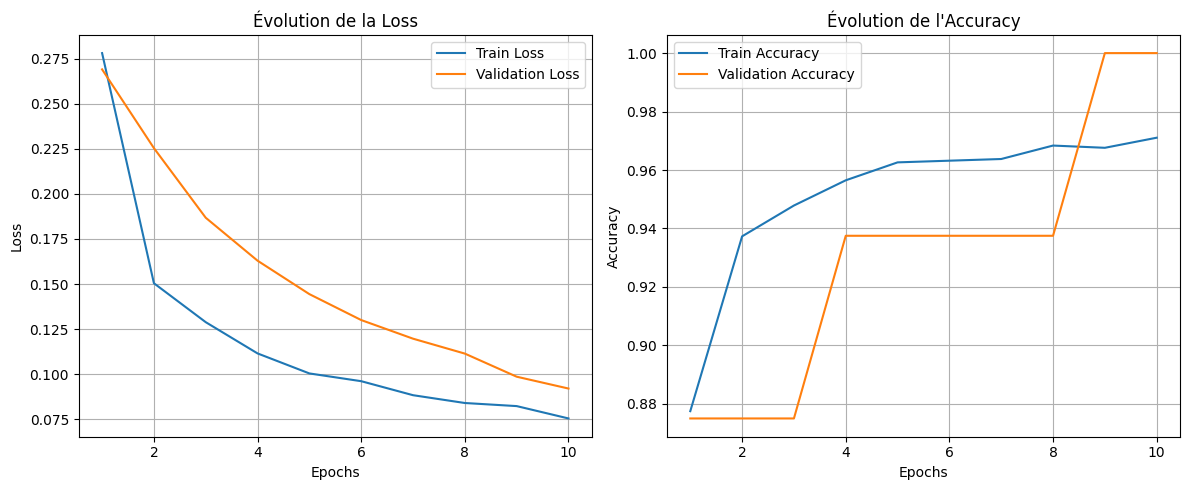

In [155]:

import matplotlib.pyplot as plt

# Récupérer les métriques de l'entraînement
training_loss = model_mobilenet.history.history["loss"]
training_accuracy = model_mobilenet.history.history["accuracy"]

val_loss = model_mobilenet.history.history["val_loss"]
val_accuracy = model_mobilenet.history.history["val_accuracy"]

# Nombre réel d'epochs exécutées
epochs = range(1, len(training_loss) + 1)

plt.figure(figsize=(12, 5))

# Graphique de la Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, training_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.title("Évolution de la Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

# Graphique de l'Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, training_accuracy, label="Train Accuracy")
plt.plot(epochs, val_accuracy, label="Validation Accuracy")
plt.title("Évolution de l'Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [156]:
model_mobilenet.evaluate(test_ds, return_dict=True)
for metric, value in model_mobilenet.evaluate(test_ds, return_dict=True).items():
    print(f"{metric} : {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 30ms/step - accuracy: 0.8103 - auc: 0.6395 - loss: 0.5570 - precision: 0.4678 - recall: 0.6615
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.8103 - auc: 0.6395 - loss: 0.5570 - precision: 0.4678 - recall: 0.6615  
accuracy : 0.8878
auc : 0.9604
loss : 0.3456
precision : 0.8509
recall : 0.9949


In [157]:
import numpy as np

y_true_mobilenet = np.concatenate([
    labels.numpy().ravel() for labels in test_ds.map(lambda x, y: y).unbatch()
])

y_prop = model_mobilenet.predict(test_ds, verbose=1).ravel()

THRESHOLD = 0.5
y_pred = (y_prop >= THRESHOLD).astype(int)


20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 221ms/step


In [158]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true_mobilenet,
    y_pred,
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

              precision    recall  f1-score   support

      NORMAL       0.99      0.71      0.83       234
   PNEUMONIA       0.85      0.99      0.92       390

    accuracy                           0.89       624
   macro avg       0.92      0.85      0.87       624
weighted avg       0.90      0.89      0.88       624



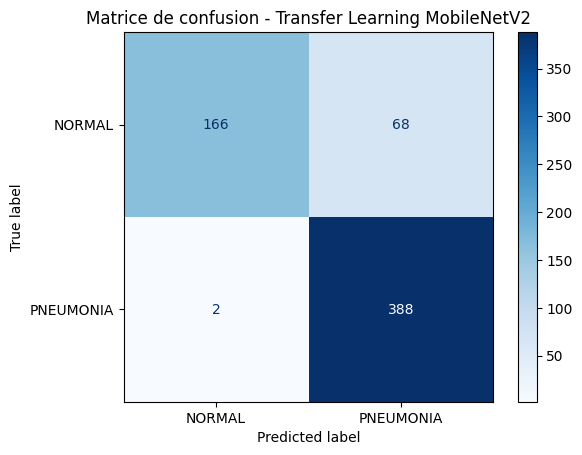

In [159]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt
import numpy as np

# Calculer la matrice de confusion
cm = confusion_matrix(
    y_true_mobilenet,
    y_pred
)

# Afficher la matrice
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - Transfer Learning MobileNetV2")
plt.show()




In [162]:
model_mobilenet.save("chest_xray_mobilenet.keras")

## fine tunning 

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

IMG_SIZE = (180, 180)
base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    input_shape=(180, 180, 3), 
    include_top=False,
)
print("mobileNetV2 chargé avec succès")


/tmp/ipykernel_874/4138024184.py:5: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = tf.keras.applications.MobileNetV2(


mobileNetV2 chargé avec succès


In [ ]:
base_model.trainable = True

In [ ]:
fine_tune_at =len(base_model.layers) - 30

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

In [ ]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.03),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomZoom(
        height_factor=0.5,
        width_factor=0.5
    )
])

In [ ]:
from tensorflow.keras import layers, Model
from tensorflow.keras import Sequential

model_mobilnet_fine_tunning = Sequential([
    layers.Input(shape=(180, 180, 3)),

    data_augmentation,

    layers.Rescaling(1./127.5, offset=-1),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])

model_mobilnet_fine_tunning.summary()

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_7 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 6, 6, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,527,681 (5.83 MB)

 Non-trainable params: 731,584 (2.79 MB)

In [ ]:
import tensorflow.keras.optimizers as optimizers
from tensorflow.keras.metrics import BinaryAccuracy ,Precision,Recall,AUC
model_mobilnet_fine_tunning.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
            BinaryAccuracy(name="accuracy"),
            Precision(name="precision"),
            Recall(name="recall"),
            AUC(name="auc"),
    ]

)


In [ ]:
import time
start = time.time()
history_fine = model_mobilnet_fine_tunning.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr]
)

end = time.time()

duration_fine_tuning = end - start
print(f"Durée d'entraînement Fine-Tuning : {duration_fine_tuning:.2f} secondes")
print(f"Durée en minutes : {duration_fine_tuning / 60:.2f} minutes")

Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 26s 100ms/step - accuracy: 0.5071 - auc: 0.7703 - loss: 0.6411 - precision: 0.9171 - recall: 0.3552 - val_accuracy: 0.6875 - val_auc: 0.7812 - val_loss: 0.5946 - val_precision: 0.8000 - val_recall: 0.5000 - learning_rate: 1.0000e-05
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step - accuracy: 0.8519 - auc: 0.9412 - loss: 0.3321 - precision: 0.9541 - recall: 0.8395 - val_accuracy: 0.6250 - val_auc: 0.7812 - val_loss: 0.5745 - val_precision: 0.6000 - val_recall: 0.7500 - learning_rate: 1.0000e-05
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 14s 84ms/step - accuracy: 0.8979 - auc: 0.9644 - loss: 0.2566 - precision: 0.9740 - recall: 0.8849 - val_accuracy: 0.6875 - val_auc: 0.7969 - val_loss: 0.6049 - val_precision: 0.6364 - val_recall: 0.8750 - learning_rate: 1.0000e-05
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9058 - auc: 0.9705 - loss: 0.2303 - precision: 0.9716 - recall: 0.8976
Epoch 4: ReduceLROnPlateau reducing learning 

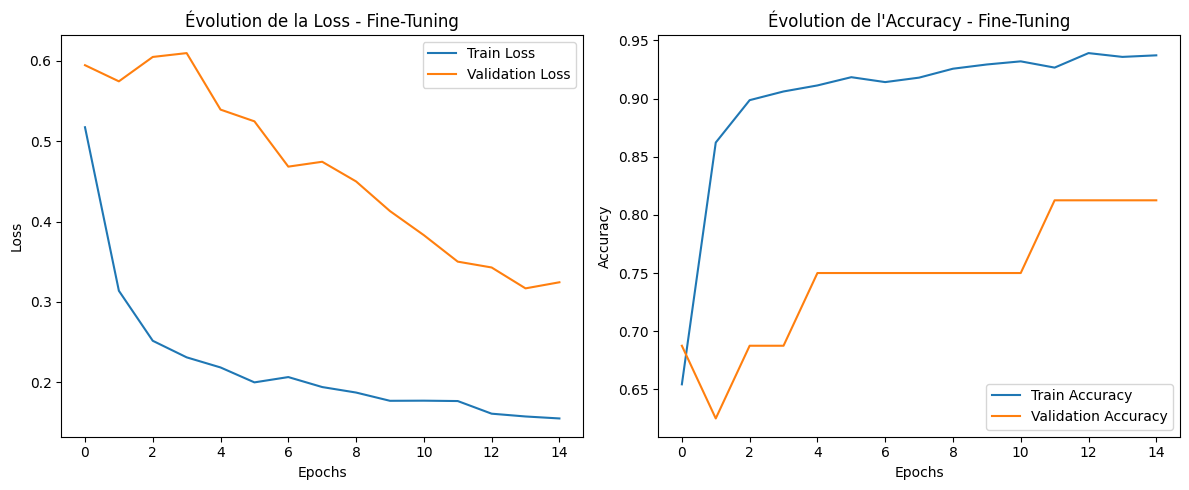

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_fine.history["loss"], label="Train Loss")
plt.plot(history_fine.history["val_loss"], label="Validation Loss")
plt.title("Évolution de la Loss - Fine-Tuning")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.subplot(1, 2, 2)


plt.plot(history_fine.history["accuracy"], label="Train Accuracy")
plt.plot(history_fine.history["val_accuracy"], label="Validation Accuracy")
plt.title("Évolution de l'Accuracy - Fine-Tuning")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
model_mobilnet_fine_tunning.evaluate(test_ds, return_dict=True)
for metric, value in model_mobilnet_fine_tunning.evaluate(test_ds, return_dict=True).items():
    print(f"{metric} : {value:.4f}")


20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.8593 - auc: 0.6421 - loss: 0.3248 - precision: 0.5087 - recall: 0.6223
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.8593 - auc: 0.6421 - loss: 0.3248 - precision: 0.5087 - recall: 0.6223
accuracy : 0.9038
auc : 0.9676
loss : 0.2358
precision : 0.8947
recall : 0.9590


In [ ]:
import numpy as np

y_true_finne_tuning = np.concatenate([
    labels.numpy().ravel()
    for image ,labels in test_ds
]).astype(int)

y_prob_fine_tuning = model_mobilnet_fine_tunning.predict(test_ds, verbose=1).ravel()

THRESHOLD = 0.5
y_pred_fine_tuning = (y_prob_fine_tuning >= THRESHOLD).astype(int)

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step


In [ ]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true_finne_tuning,
    y_pred_fine_tuning,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

              precision    recall  f1-score   support

      NORMAL       0.92      0.81      0.86       234
   PNEUMONIA       0.89      0.96      0.93       390

    accuracy                           0.90       624
   macro avg       0.91      0.89      0.89       624
weighted avg       0.91      0.90      0.90       624



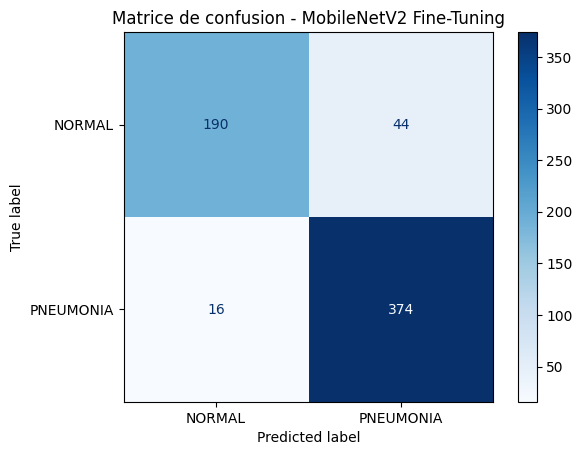

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true_finne_tuning,
    y_pred_fine_tuning,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matrice de confusion - MobileNetV2 Fine-Tuning")
plt.show()

In [ ]:
model_mobilnet_fine_tunning.save("chest_xray_fine_tuning.keras")

## comparaison entre les trois model 

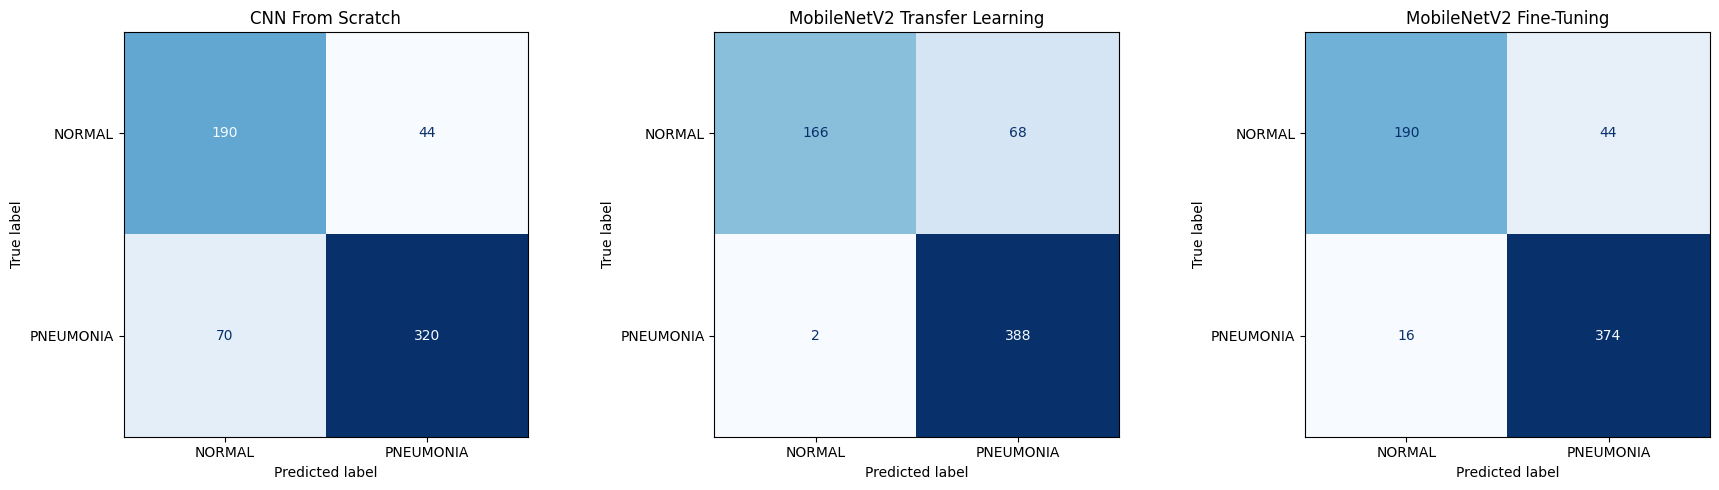

In [161]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 1. Récupérer les vraies étiquettes du jeu de test
y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

# 2. Faire les prédictions des trois modèles
models_list = [
    ("CNN From Scratch", model),
    ("MobileNetV2 Transfer Learning", model_mobilenet),
    ("MobileNetV2 Fine-Tuning", model_mobilnet_fine_tunning)
]

# 3. Afficher les trois matrices côte à côte
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, current_model) in zip(axes, models_list):

    # Probabilités prédites
    y_prob = current_model.predict(test_ds, verbose=0).ravel()

    # Transformer les probabilités en classes
    y_pred = (y_prob >= 0.5).astype(int)

    # Calculer la matrice de confusion
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    # Afficher la matrice
    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["NORMAL", "PNEUMONIA"]
    )

    display.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(model_name)

plt.tight_layout()
plt.show()